# Examples of the 100-best clean EODs per fish per recording (24 recordings, one random EOD each)

**Set** (`best100_per_fish_per_recording_71.csv`): in each of the 71 recordings, per fish, the 100 EODs with the lowest shape L2
(Denis' model, patterns scaled to max |v| = 1) among those that pass the clean-emitter rules: good masks for all four fish;
emitter ≥ 10 cm from every other fish; lowest shape L2 of the four fish; its 2 nearest pairs = the 2 loudest recorded pairs with
the model's sign; every other fish ≤ ½ its predicted |v| on those pairs.

**Examples**: for each fish, one EOD drawn at random (seed 0) in each of the 24 every-third recordings (00_12_52, 01_12_53, ...,
23_36_27) where that fish has EODs in the set. Those 24 recordings also have my model in the camera tank (L-barriers, interior
4 × water, N 150) for every EOD frame, so both models are shown.

**Each figure**: tank with Kaden's masks (emitter in a dashed box, its 2 nearest pairs joined); a zoom on every fish with its mask
midline; **my model** — recorded main-phase pattern and every fish's unit-current prediction (MODEL_SIGN × u), each scaled to max
|v| = 1, with shape L2; **Denis' model** — recorded peak-to-peak and his prediction for every fish, each scaled to max |v| = 1, with
shape L2; recorded traces of all 10 pairs. Grey bands: the emitter's 2 nearest pairs.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle
from matplotlib.backends.backend_pdf import PdfPages
from io_utils import load_masks
from eod_assign import load_electrode_pairs, recorded_pair_traces_all, MODEL_SIGN
from kaden_4fish_assign import kaden_pkl
%matplotlib inline

BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
SRC = f'{BASE}/clean_emitter_set_71'
OUT = f'{SRC}/best100_examples'; os.makedirs(f'{OUT}/per_frame', exist_ok=True)
EL = pd.read_csv('data/electrodes/electrodes_signed_px_coord_4-fish.csv').sort_values('pair').reset_index(drop=True)
PIDS = [p for p, _, _ in load_electrode_pairs('data/electrodes/electrode_locations_updated_4-fish.csv', P)]
PX_CM = P / 60
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
L_CM = {'A': 15.65, 'B': 13.10, 'C': 9.82, 'D': 8.51}
MODEL = 'model_N150_tank_barriers_int4_by_frame.pkl'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
REC24 = open(f'{BASE}/tank_geometry/every_third_24.txt').read().split()
S = pd.read_csv(f'{SRC}/best100_per_fish_per_recording_71.csv')
rng = np.random.default_rng(0)
PK = pd.concat([g.iloc[[rng.integers(len(g))]] for (t, f), g in S[S.video.isin(REC24)].groupby(['video', 'fish'])], ignore_index=True)
PK = PK.sort_values(['fish', 'video']).reset_index(drop=True)
PK.to_csv(f'{OUT}/best100_examples.csv', index=False)
print(f'{len(PK)} examples'); display(pd.crosstab(PK.video, PK.fish, margins=True).T)

84 examples


video,00_12_52,01_12_53,02_12_53,03_12_54,04_12_54,05_12_55,06_12_55,07_12_56,08_12_56,09_12_56,...,15_16_23,16_16_23,17_16_24,18_16_24,19_16_25,20_16_25,21_36_26,22_36_26,23_36_27,All
fish,,,,,,,,,,,,,,,,,,,,,
A,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,22
B,0,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,22
C,1,1,1,1,1,1,1,1,1,1,...,1,1,0,1,1,1,1,1,1,22
D,1,1,1,1,1,1,1,1,1,0,...,0,1,0,1,1,1,1,0,1,18
All,3,4,4,4,4,4,4,4,4,3,...,3,4,2,4,4,4,4,3,4,84


loaded 84 frames


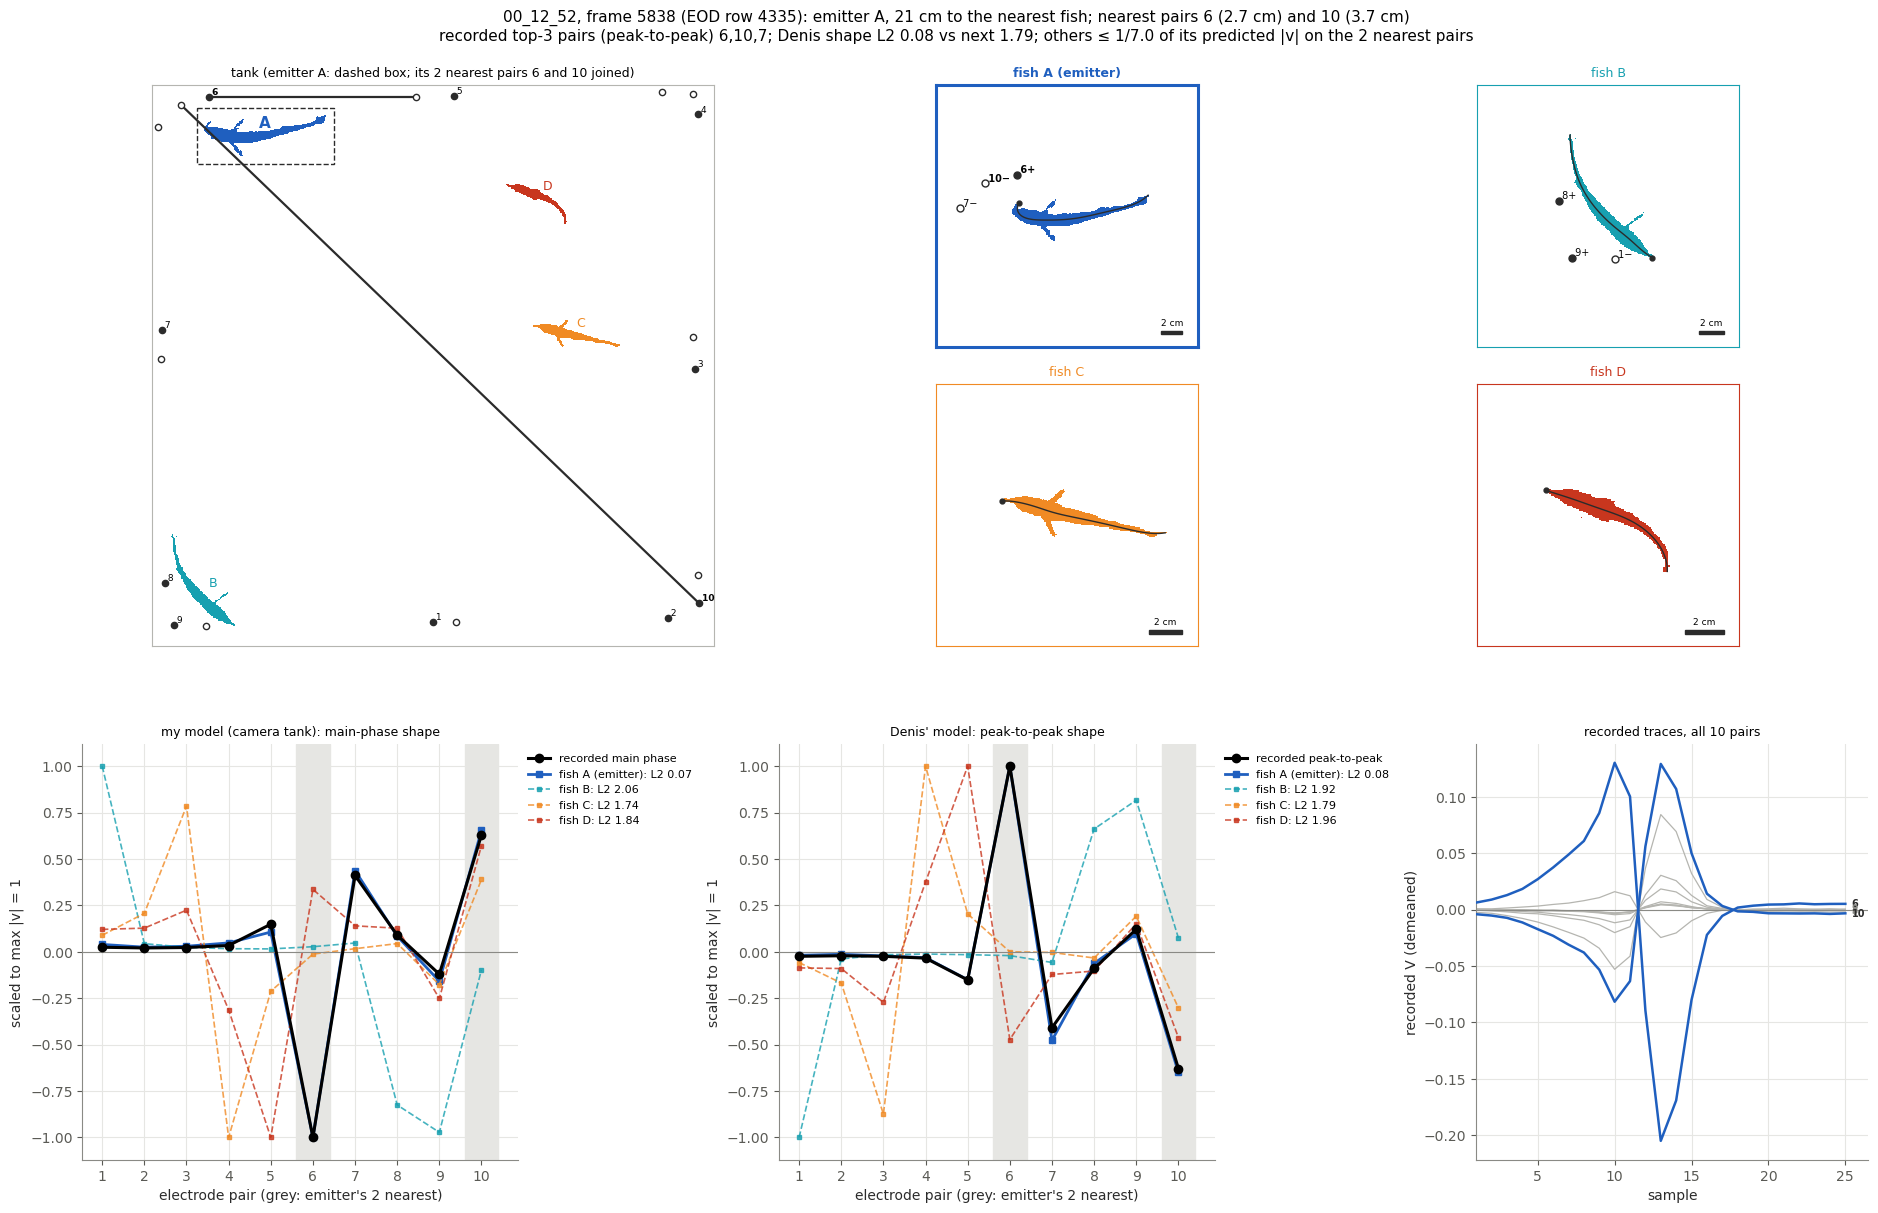

fish A: 22 figures -> results/eod_assign_4fish_kaden/clean_emitter_set_71/best100_examples/best100_examples_fish_A.pdf


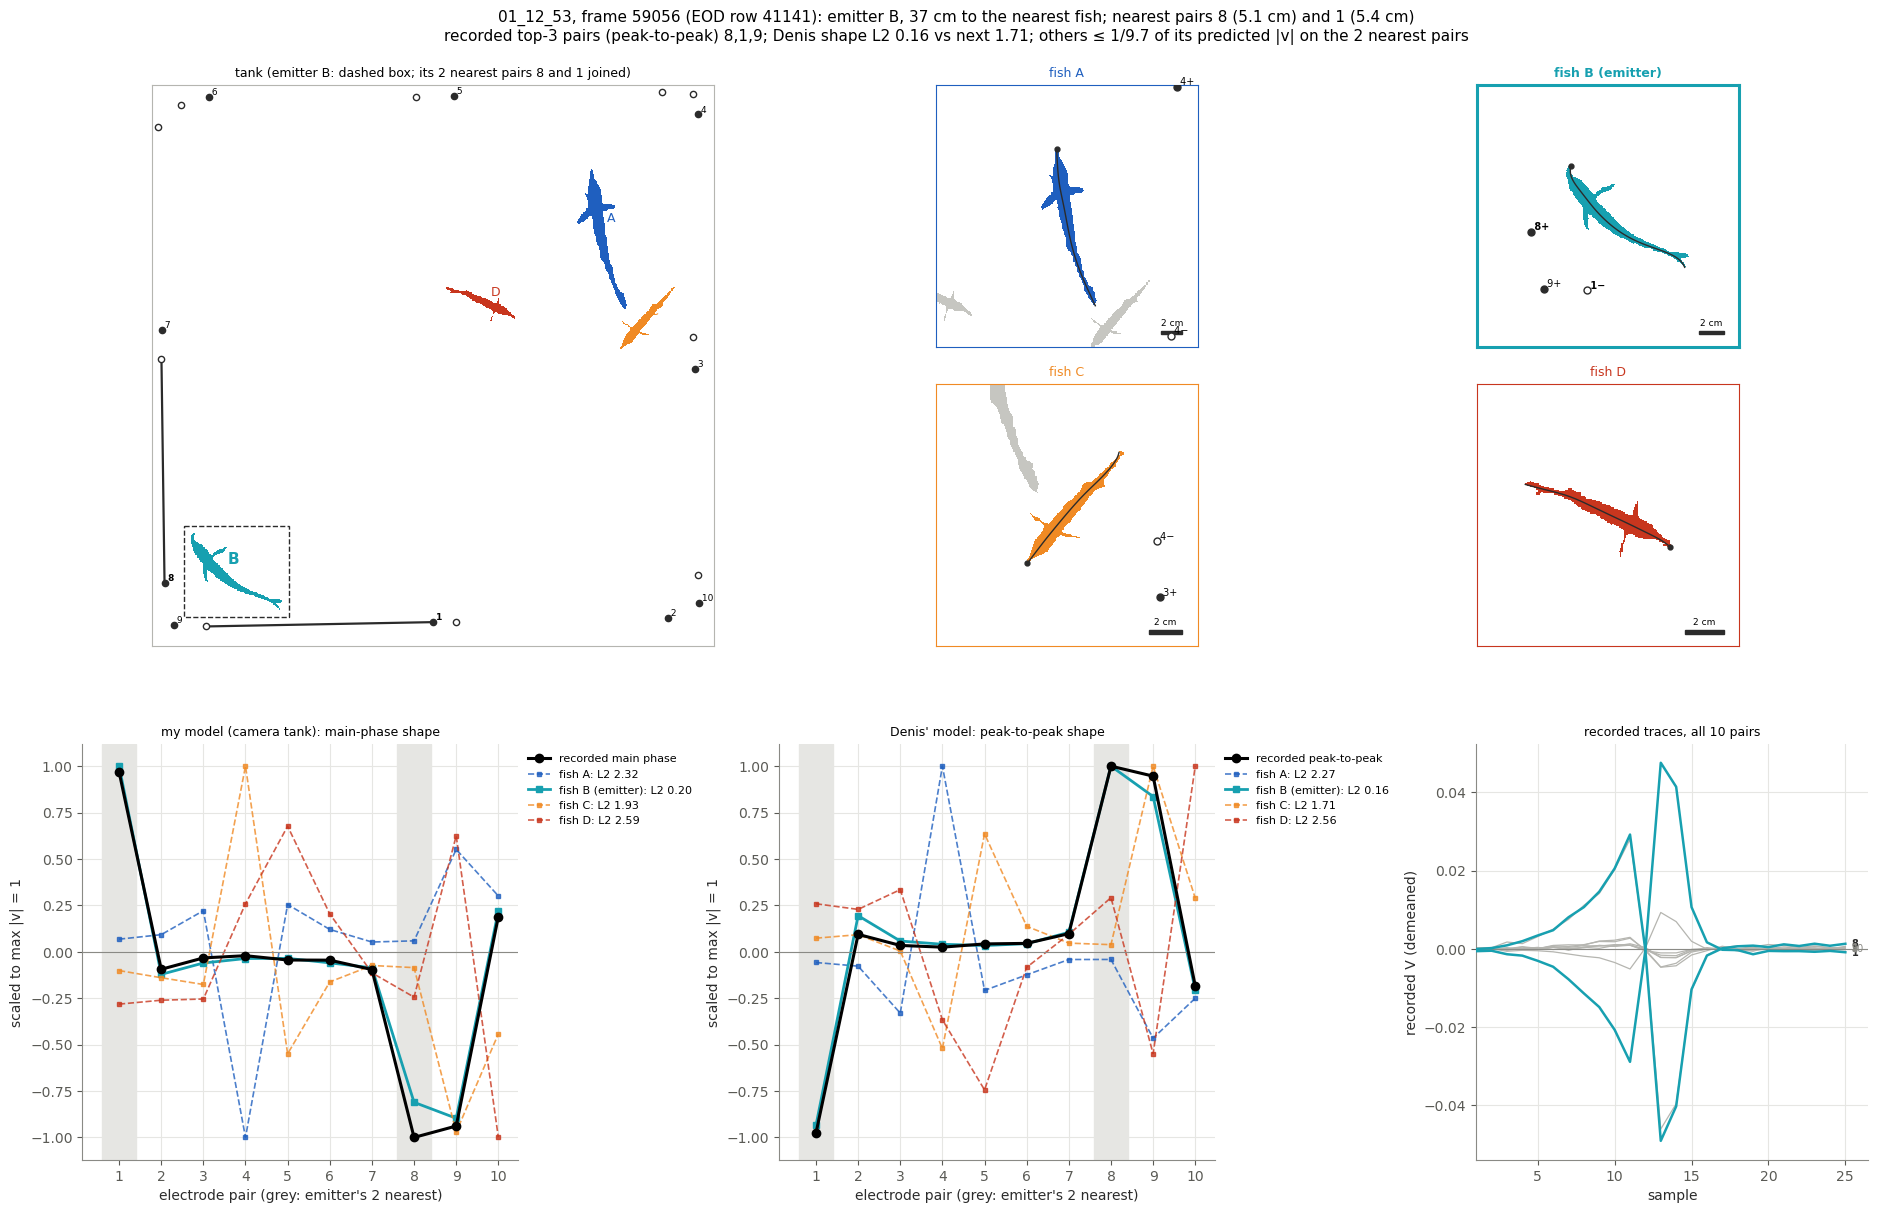

fish B: 22 figures -> results/eod_assign_4fish_kaden/clean_emitter_set_71/best100_examples/best100_examples_fish_B.pdf


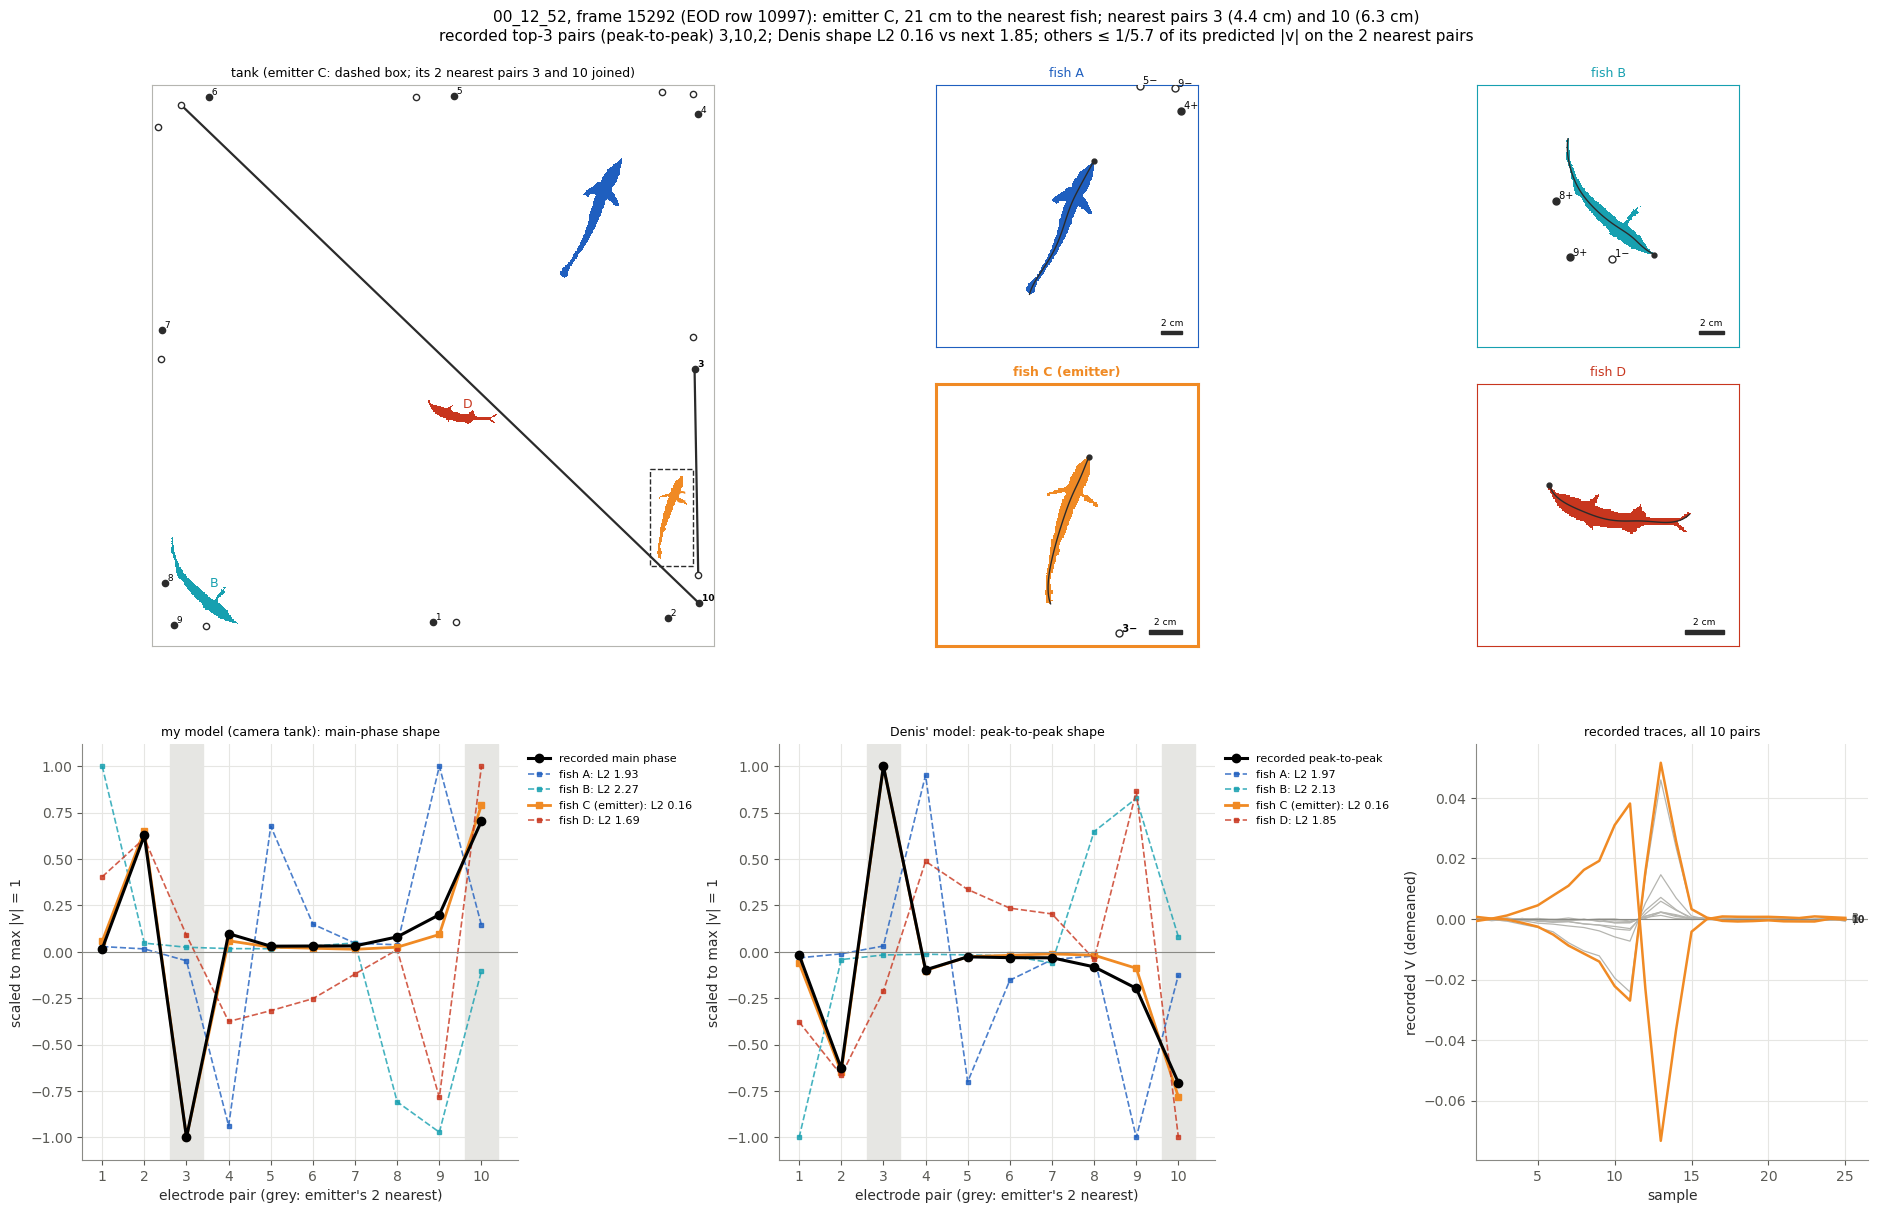

fish C: 22 figures -> results/eod_assign_4fish_kaden/clean_emitter_set_71/best100_examples/best100_examples_fish_C.pdf


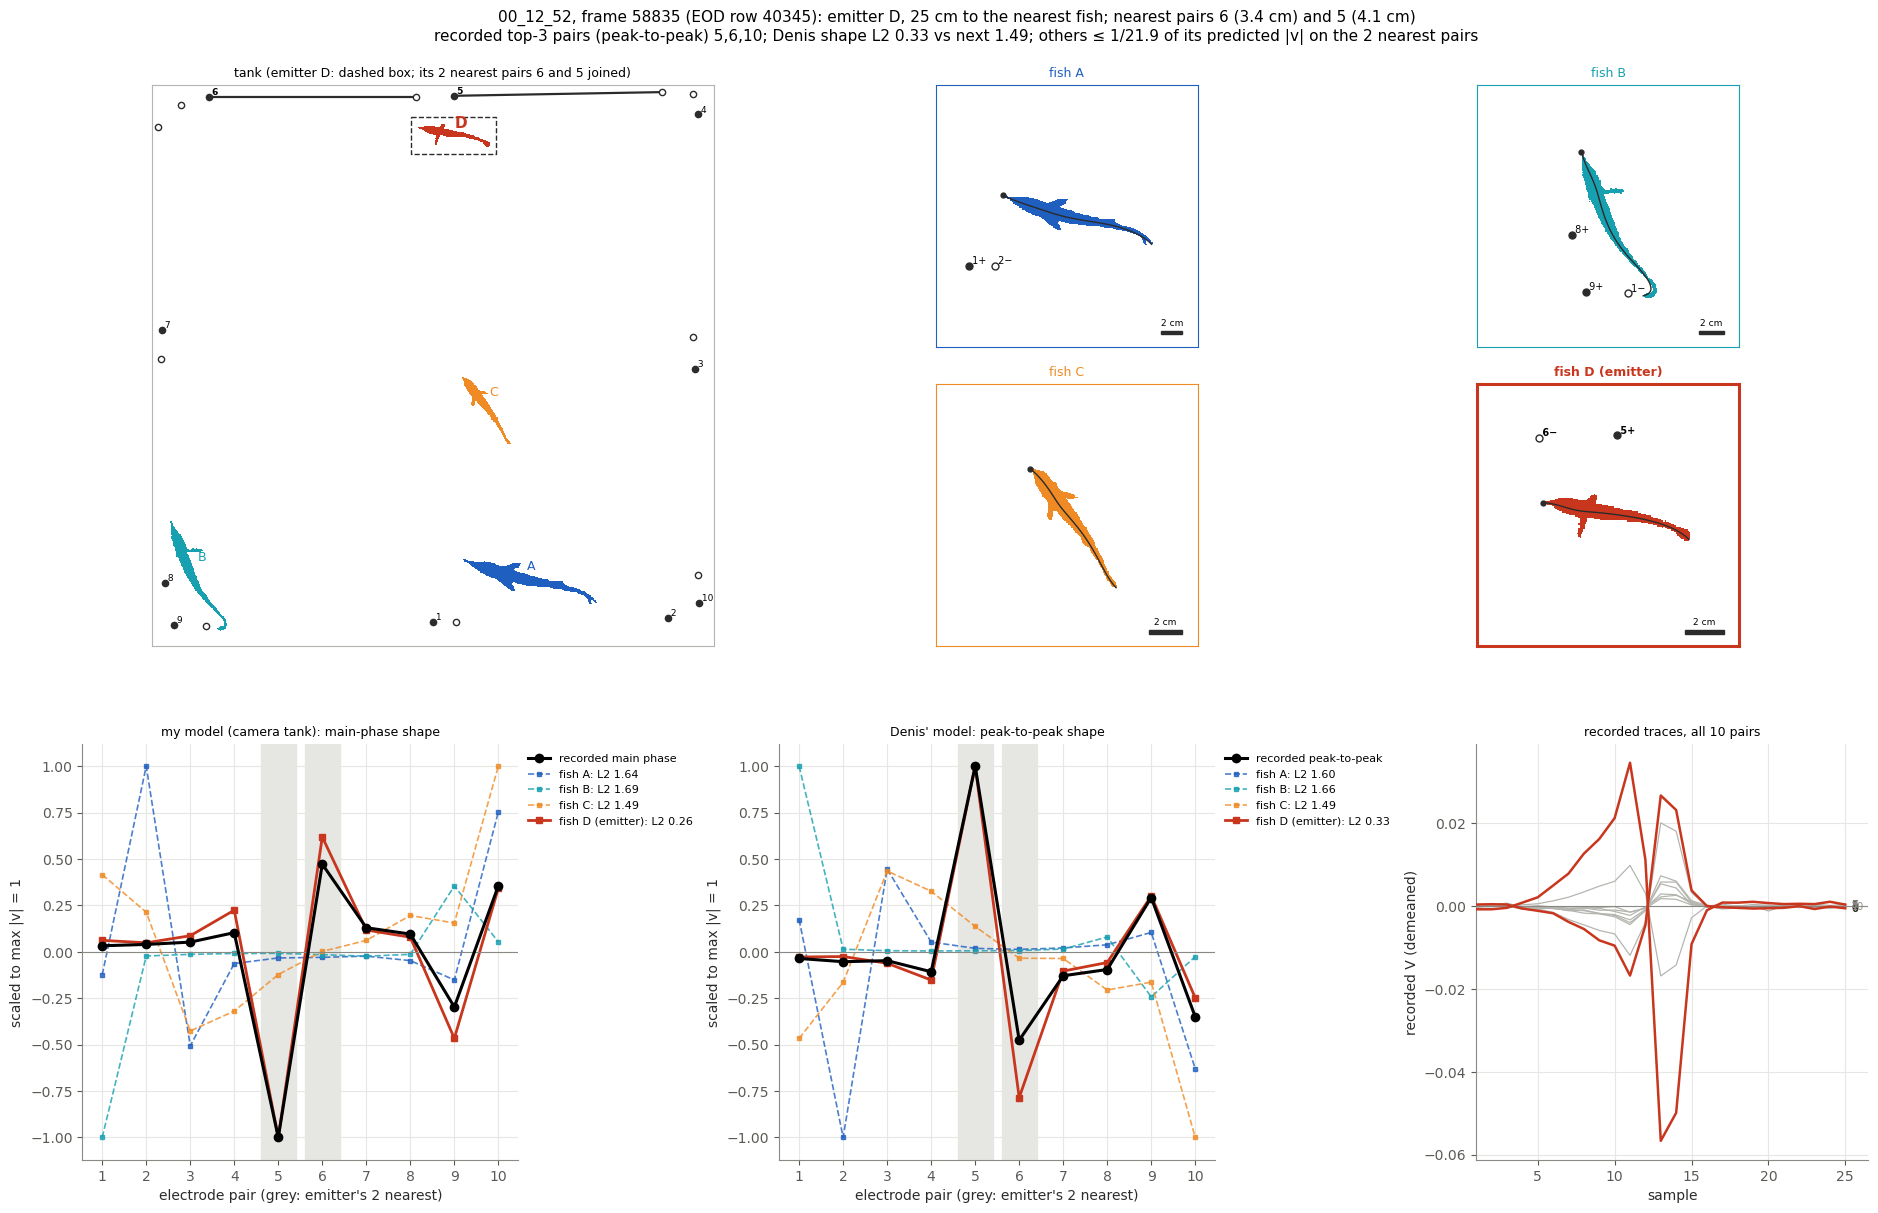

fish D: 18 figures -> results/eod_assign_4fish_kaden/clean_emitter_set_71/best100_examples/best100_examples_fish_D.pdf


In [2]:
masks, mids, TR, DREC, DPRED, MINE = {}, {}, {}, {}, {}, {}
for t in PK.video.unique():
    g = PK[PK.video == t]
    mk = load_masks(kaden_pkl(t))
    for k in g.Frame.unique(): masks[(t, int(k))] = np.asarray(mk[int(k)])
    del mk
    z = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); idx = {int(k): i for i, k in enumerate(z['frames'])}; mm_ = z['mids']
    for k in g.Frame.unique(): mids[(t, int(k))] = mm_[idx[int(k)]] * (P - 1)
    rows = np.sort(g.row.to_numpy()); keep = set(rows.tolist())
    df = pd.read_csv(f'data/4 fish/Data_4fish_2024-02-20T{t}.csv', usecols=[f'electrode_{p}_time_{i}' for p in PIDS for i in range(1, 26)],
                     skiprows=lambda i: i > 0 and (i - 1) not in keep)
    Vt = recorded_pair_traces_all(df, PIDS, 25); del df
    dv = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz', allow_pickle=True); U = pd.read_pickle(f'{BASE}/{t}/{MODEL}')
    fr = dict(zip(g.row, g.Frame))
    for k, rw in enumerate(rows):
        TR[(t, int(rw))] = Vt[k]; DREC[(t, int(rw))] = dv['recorded_ptp'][rw]; DPRED[(t, int(rw))] = dv['predicted_ptp'][rw]
        MINE[(t, int(rw))] = MODEL_SIGN * U[int(fr[rw])]
print(f'loaded {len(masks)} frames')

def draw_electrodes(ax, hit_pairs, lim=None, fs=6.5, ms=4.5):
    for _, e in EL.iterrows():
        pp = (e.x1, e.y1) if str(e.pol1).strip() == '+' else (e.x2, e.y2)
        mm_ = (e.x2, e.y2) if str(e.pol1).strip() == '+' else (e.x1, e.y1)
        hit = int(e.pair) in hit_pairs
        if lim is None and hit: ax.plot([pp[0], mm_[0]], [pp[1], mm_[1]], color='#2b2b2b', lw=1.6, zorder=2)
        for pt, filled in ((pp, True), (mm_, False)):
            if lim is not None and not (lim[0] <= pt[0] <= lim[1] and lim[2] <= pt[1] <= lim[3]): continue
            ax.plot(*pt, 'o', ms=ms, mfc='#2b2b2b' if filled else 'white', mec='#2b2b2b', mew=1, zorder=3)
            if filled or lim is not None:
                ax.text(pt[0], pt[1], f' {int(e.pair)}' + ('' if lim is None else ('+' if filled else '−')), fontsize=fs,
                        color='#000000', fontweight='bold' if hit else 'normal', va='bottom', zorder=3)

def tank(ax, r, m, near):
    img = np.ones((P, P, 3))
    for j, f in enumerate(LET): img[m[j]] = to_rgb(FISH_COL[f])
    ax.imshow(img, origin='upper', extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    for j, f in enumerate(LET):
        if m[j].any():
            yy, xx = np.nonzero(m[j])
            ax.text(xx.mean() + 18, yy.mean() - 18, f, fontsize=11 if f == r.fish else 9, color=FISH_COL[f],
                    fontweight='bold' if f == r.fish else 'normal', ha='center', va='center')
    j = LET.index(r.fish)
    if m[j].any():
        yy, xx = np.nonzero(m[j])
        ax.add_patch(Rectangle((xx.min() - 12, yy.min() - 12), xx.max() - xx.min() + 24, yy.max() - yy.min() + 24, fill=False, ec='#2b2b2b', lw=1, ls='--'))
    draw_electrodes(ax, near)
    ax.set(xlim=(0, P), ylim=(P, 0), xticks=[], yticks=[], aspect='equal'); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color('#b5b5b0')
    ax.set_title(f'tank (emitter {r.fish}: dashed box; its 2 nearest pairs {near[0]} and {near[1]} joined)', fontsize=9)

def zoom(ax, r, m, f, ml, near):
    j = LET.index(f)
    if not m[j].any():
        ax.axis('off'); ax.text(0.5, 0.5, f'fish {f}: no mask', ha='center', transform=ax.transAxes); return
    yy, xx = np.nonzero(m[j]); cy, cx = yy.mean(), xx.mean(); h = 0.8 * L_CM[f] * PX_CM
    x0, x1, y0, y1 = cx - h, cx + h, cy - h, cy + h
    img = np.ones((P, P, 3))
    for jj, g in enumerate(LET): img[m[jj]] = to_rgb(FISH_COL[g]) if g == f else (0.78, 0.78, 0.76)
    ax.imshow(img, origin='upper', extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    if np.isfinite(ml[j]).all():
        ax.plot(ml[j][:, 1], ml[j][:, 0], color='#2b2b2b', lw=1); ax.plot(ml[j][-1, 1], ml[j][-1, 0], 'o', ms=3.5, color='#2b2b2b')
    draw_electrodes(ax, near if f == r.fish else [], lim=(x0, x1, y0, y1), fs=7, ms=5)
    sb = 2 * PX_CM
    ax.add_patch(Rectangle((x1 - 0.06 * 2 * h - sb, y1 - 0.06 * 2 * h), sb, 0.012 * 2 * h, color='#2b2b2b'))
    ax.text(x1 - 0.06 * 2 * h - sb / 2, y1 - 0.075 * 2 * h, '2 cm', fontsize=6.5, ha='center', va='bottom')
    ax.set(xlim=(x0, x1), ylim=(y1, y0), xticks=[], yticks=[], aspect='equal'); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(FISH_COL[f]); sp.set_linewidth(2.2 if f == r.fish else 0.8)
    ax.set_title(f"fish {f}{' (emitter)' if f == r.fish else ''}", fontsize=9, fontweight='bold' if f == r.fish else 'normal', color=FISH_COL[f])


def shape_panel(ax, R, Mf, near, emitter, title, rec_label):
    x = np.arange(1, 11)
    ax.plot(x, R / np.abs(R).max(), '-o', color='#000000', lw=2.2, ms=6, label=rec_label, zorder=5)
    for j, f in enumerate(LET):
        if not np.isfinite(Mf[j]).all(): continue
        e = f == emitter; ps = Mf[j] / np.abs(Mf[j]).max(); l2 = np.linalg.norm(R / np.abs(R).max() - ps)
        ax.plot(x, ps, marker='s', color=FISH_COL[f], lw=2 if e else 1.2, ms=5 if e else 3.5, ls='-' if e else '--', alpha=1 if e else 0.8,
                label=f'fish {f}{" (emitter)" if e else ""}: L2 {l2:.2f}')
    for p in near: ax.axvspan(p - 0.4, p + 0.4, color='#e6e6e3', zorder=0)
    ax.axhline(0, color='#8a8a85', lw=0.8)
    ax.set(xticks=x, xlabel="electrode pair (grey: emitter's 2 nearest)", ylabel='scaled to max |v| = 1', ylim=(-1.12, 1.12))
    ax.set_title(title, fontsize=9); ax.legend(fontsize=8, frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))

def traces(axt, V, near, emitter):
    s = np.arange(1, 26)
    for p in range(1, 11):
        hit = p in near
        axt.plot(s, V[p - 1], color=FISH_COL[emitter] if hit else '#b5b5b0', lw=1.8 if hit else 0.9, zorder=3 if hit else 2)
        axt.text(25.4, V[p - 1, -1], str(p), fontsize=7, va='center', color='#2b2b2b' if hit else '#8a8a85', fontweight='bold' if hit else 'normal')
    axt.axhline(0, color='#8a8a85', lw=0.8); axt.set(xlabel='sample', ylabel='recorded V (demeaned)', xlim=(1, 26.5))
    axt.set_title('recorded traces, all 10 pairs', fontsize=9)

def frame_figure(r):
    key = (r.video, int(r.Frame)); m = masks[key]; ml = mids[key]; near = [int(r.nearest_pair), int(r.second_pair)]; rk = (r.video, int(r.row))
    V = TR[rk]; R = V[:, np.abs(V).max(0).argmax()]
    fig = plt.figure(figsize=(19, 12.5))
    gs = fig.add_gridspec(2, 3, height_ratios=[1.35, 1], width_ratios=[1.35, 1, 1], hspace=0.2, wspace=0.04, top=0.92, bottom=0.06, left=0.04, right=0.98)
    tank(fig.add_subplot(gs[0, 0]), r, m, near)
    gz = gs[0, 1:].subgridspec(2, 2, hspace=0.14, wspace=0.04)
    for j, f in enumerate(LET): zoom(fig.add_subplot(gz[j // 2, j % 2]), r, m, f, ml, near)
    gb = gs[1, :].subgridspec(1, 3, wspace=0.62, width_ratios=[1, 1, 0.9])
    shape_panel(fig.add_subplot(gb[0]), R, MINE[rk], near, r.fish, 'my model (camera tank): main-phase shape', 'recorded main phase')
    shape_panel(fig.add_subplot(gb[1]), DREC[rk], DPRED[rk], near, r.fish, "Denis' model: peak-to-peak shape", 'recorded peak-to-peak')
    traces(fig.add_subplot(gb[2]), V, near, r.fish)
    fig.suptitle(f'{r.video}, frame {int(r.Frame)} (EOD row {int(r.row)}): emitter {r.fish}, {r.gap_cm:.0f} cm to the nearest fish; nearest pairs '
                 f'{near[0]} ({r.dist_nearest_cm:.1f} cm) and {near[1]} ({r.dist_second_cm:.1f} cm)\nrecorded top-3 pairs (peak-to-peak) {r.rec_top3_pairs}; '
                 f'Denis shape L2 {r.L2_fish:.2f} vs next {r.L2_next_best:.2f}; others ≤ 1/{r.dom_min:.1f} of its predicted |v| on the 2 nearest pairs', fontsize=11)
    return fig

for f in LET:
    g = PK[PK.fish == f]
    with PdfPages(f'{OUT}/best100_examples_fish_{f}.pdf') as pdf:
        for n, (_, r) in enumerate(g.iterrows()):
            fig = frame_figure(r)
            fig.savefig(f'{OUT}/per_frame/fish_{f}_{r.video}_frame{int(r.Frame)}.png', dpi=85)
            pdf.savefig(fig)
            if n == 0: plt.show()
            else: plt.close(fig)
    print(f'fish {f}: {len(g)} figures -> {OUT}/best100_examples_fish_{f}.pdf')